# 🔍 Análise de Dados – Restaurantes do iFood

**Base:** [iFood Restaurants Data](https://www.kaggle.com/datasets/ricardotachinardi/ifood-restaurants-data) (Kaggle, Ricardo Tachinardi) —
dados públicos do marketplace do iFood coletados em **nov/2020** e **fev/2021**, com cerca de 400 mil restaurantes de todo o Brasil.

**Perguntas:**
1. Os dados estão confiáveis? O que precisou ser corrigido?
2. A nota média de um restaurante diz o que parece dizer?
3. Tempo de entrega, preço e categoria se relacionam com a nota?
4. Como a plataforma mudou entre nov/2020 e fev/2021?

> Cada linha é um **restaurante**, não um pedido. A base não tem comentários nem nota por pedido; a nota é a média exibida no app.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path("..") / "src"))

import pandas as pd
from IPython.display import Image, display

import limpeza, analise
pd.set_option("display.max_columns", 30)

## 1. Conhecendo a base bruta

In [2]:
bruto = pd.read_csv("../data/raw/ifood-restaurants-february-2021.csv", low_memory=False)
print(bruto.shape)
bruto.drop(columns=["avatar", "paymentCodes", "tags"]).head()

(406399, 14)


,availableForScheduling,category,delivery_fee,delivery_time,distance,ibge,minimumOrderValue,name,price_range,rating,url
0,False,Marmita,3.99,27,1.22,5300108,10.0,Cantina Arte & Sabor,CHEAPEST,0.0,https://www.ifood.com.br/delivery/brasilia-df/...
1,False,Açaí,7.99,61,4.96,5300108,10.0,Raruty Açaí Raiz,CHEAPEST,0.0,https://www.ifood.com.br/delivery/brasilia-df/...
2,False,Bebidas,11.99,70,8.35,5300108,5.0,Toma na Kombi,MODERATE,0.0,https://www.ifood.com.br/delivery/brasilia-df/...
3,False,Carnes,16.49,63,6.35,5300108,20.0,Churrasquinho do Barriga´s,CHEAPEST,0.0,https://www.ifood.com.br/delivery/brasilia-df/...
4,False,Brasileira,11.99,58,5.22,5300108,20.0,Prime Restaurante,CHEAPEST,0.0,https://www.ifood.com.br/delivery/brasilia-df/...


In [3]:
bruto[["rating", "delivery_time", "delivery_fee", "distance", "minimumOrderValue"]].describe().round(2)

,rating,delivery_time,delivery_fee,distance,minimumOrderValue
count,406399.00,406399.00,406399.00,406399.00,406399.00
mean,2.52,47.43,6.80,4.22,276.89
std,2.29,19.66,4.32,68.33,157066.76
min,0.00,-1.00,0.00,0.00,0.00
25%,0.00,35.00,4.00,1.75,10.00
50%,3.96,45.00,6.00,3.08,15.00
75%,4.72,60.00,9.49,4.83,20.00
max,5.00,5050.00,35.00,11810.19,99999999.99


O `describe()` já mostra os problemas:

- **`rating` com mediana 3,96 e 25% dos valores iguais a 0.** Restaurantes com nota zero são estranhos: a menor nota real fica perto de 0,5.
- **`delivery_time` de -1 a 5.050 minutos** e **`distance` de até 11.810 km**: erros de coleta.
- **`minimumOrderValue` de R$ 99.999.999,99**: um valor-sentinela, não um pedido mínimo real.

In [4]:
print(f"Restaurantes com nota 0: {(bruto['rating'] == 0).mean():.1%}")
print(f"Notas entre 0 e 1 (exclusive): {((bruto['rating'] > 0) & (bruto['rating'] < 1)).sum()}")
print(f"Média com os zeros: {bruto['rating'].mean():.2f}  |  sem os zeros: {bruto.loc[bruto['rating'] > 0, 'rating'].mean():.2f}")

Restaurantes com nota 0: 44.1%
Notas entre 0 e 1 (exclusive): 5
Média com os zeros: 2.52  |  sem os zeros: 4.51


**A decisão mais importante do projeto:** 44% dos restaurantes têm nota 0, e quase não existem notas entre 0 e 1.
Ou seja, 0 não é uma nota ruim: é **"sem nota exibida"** (restaurante novo ou com poucas avaliações).

Tratar o zero como nota derrubaria a média de **4,51 para 2,52** e faria qualquer comparação entre grupos medir,
na verdade, *quantos restaurantes sem nota* cada grupo tem.

## 2. Limpeza

Toda a limpeza está em `src/limpeza.py`:

| Problema | Decisão | Por quê |
|---|---|---|
| Nota 0 | vira "sem nota" (`tem_nota = False`, `nota = NaN`) | não é avaliação ruim; distorce todas as médias |
| Tempo fora de 5–180 min | vira nulo | -1, 0 e 5.050 min são erros de coleta |
| Distância > 50 km | vira nulo | erro de geolocalização (até 11.810 km) |
| Pedido mínimo > R$ 500 | vira nulo | valor-sentinela de R$ 99.999.999,99 |
| Código IBGE | substituído pela cidade/UF da URL | o IBGE é do ponto de busca, não do restaurante |
| Faixa de preço `CHEAPEST`… | traduzida e ordenada | leitura e ordenação nos gráficos |

Valores inválidos viram **nulo** em vez de apagar a linha: um restaurante com tempo de entrega errado ainda tem nota e categoria válidas.

In [5]:
qualidade = pd.read_csv("../reports/qualidade_dados.csv")
qualidade

,coleta,etapa,linhas,detalhe
0,fev/2021,Base original,406399,14 colunas
1,fev/2021,Duplicatas por id removidas,0,id = último trecho da URL
2,fev/2021,Cidade/UF extraídas da URL,406399,"1553 cidades, 27 UFs; 0 sem região"
3,fev/2021,Nota 0 tratada como 'sem nota',179157,44.1% da base; a menor nota real é 0.5
4,fev/2021,Tempos de entrega implausíveis anulados,255,"fora de 5–180 min (mín. -1, máx. 5050)"
5,fev/2021,Distâncias implausíveis anuladas,201,"> 50 km (máx. 11,810 km)"
6,fev/2021,Pedidos mínimos implausíveis anulados,59,"> R$ 500 (máx. R$ 99,999,999.99)"
7,fev/2021,Base final,406399,15 colunas
8,nov/2020,Base original,361447,11 colunas
9,nov/2020,Duplicatas por id removidas,0,id = último trecho da URL


In [6]:
fev, nov = analise.carregar()
fev.head()

,id,nome,categoria,uf,regiao,cidade_slug,tem_nota,nota,tempo_entrega,taxa_entrega,frete_gratis,distancia_km,faixa_preco,pedido_minimo,tag_novo
0,136c9a0c-02fb-4cf6-90b6-c4e89bd43c5b,Cantina Arte & Sabor,Marmita,DF,Centro-Oeste,brasilia,False,NaN,27.0,3.99,False,1.22,1 - Mais barato,10.0,True
1,5608d2c8-91b8-4bad-b905-63ed030b5797,Raruty Açaí Raiz,Açaí,DF,Centro-Oeste,brasilia,False,NaN,61.0,7.99,False,4.96,1 - Mais barato,10.0,True
2,33bf98af-fbbc-4ea8-9fe6-086f5a2db064,Toma na Kombi,Bebidas,DF,Centro-Oeste,brasilia,False,NaN,70.0,11.99,False,8.35,3 - Moderado,5.0,True
3,10d4b6c4-3481-42f4-a1f6-204acc437db5,Churrasquinho do Barriga´s,Carnes,DF,Centro-Oeste,brasilia,False,NaN,63.0,16.49,False,6.35,1 - Mais barato,20.0,True
4,16e90495-f316-4f64-b5a7-d325f4bc2177,Prime Restaurante,Brasileira,DF,Centro-Oeste,brasilia,False,NaN,58.0,11.99,False,5.22,1 - Mais barato,20.0,True


## 3. Análise exploratória

### 3.1 Como as notas se distribuem

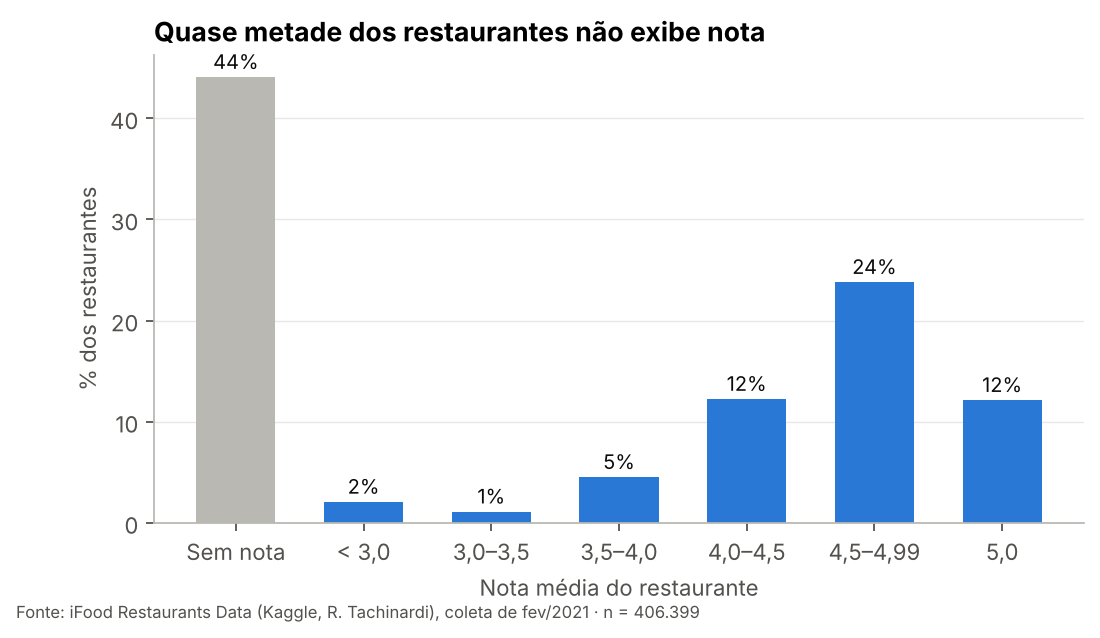

Nota média: 4.51 | mediana: 4.67 | nota 5,0: 21.7% | abaixo de 4,0: 10.9%


In [7]:
analise.fig_distribuicao_notas(fev)
display(Image("../figures/01_distribuicao_notas.png"))
com_nota = fev[fev["tem_nota"]]
print(f"Nota média: {com_nota['nota'].mean():.2f} | mediana: {com_nota['nota'].median():.2f} | "
      f"nota 5,0: {(com_nota['nota'] == 5).mean():.1%} | abaixo de 4,0: {(com_nota['nota'] < 4).mean():.1%}")

Entre os restaurantes avaliados, as notas são **muito concentradas no topo**: a mediana é 4,67 e **22% têm nota 5,0**.
Só 11% ficam abaixo de 4,0. Na prática, a nota média tem pouco poder de diferenciar restaurantes: a diferença entre
"bom" e "ruim" está espremida em poucos décimos.

*Limitação:* a base não traz o número de avaliações. Muitos 5,0 provavelmente são restaurantes com poucas avaliações.

### 3.2 Tempo de entrega e nota

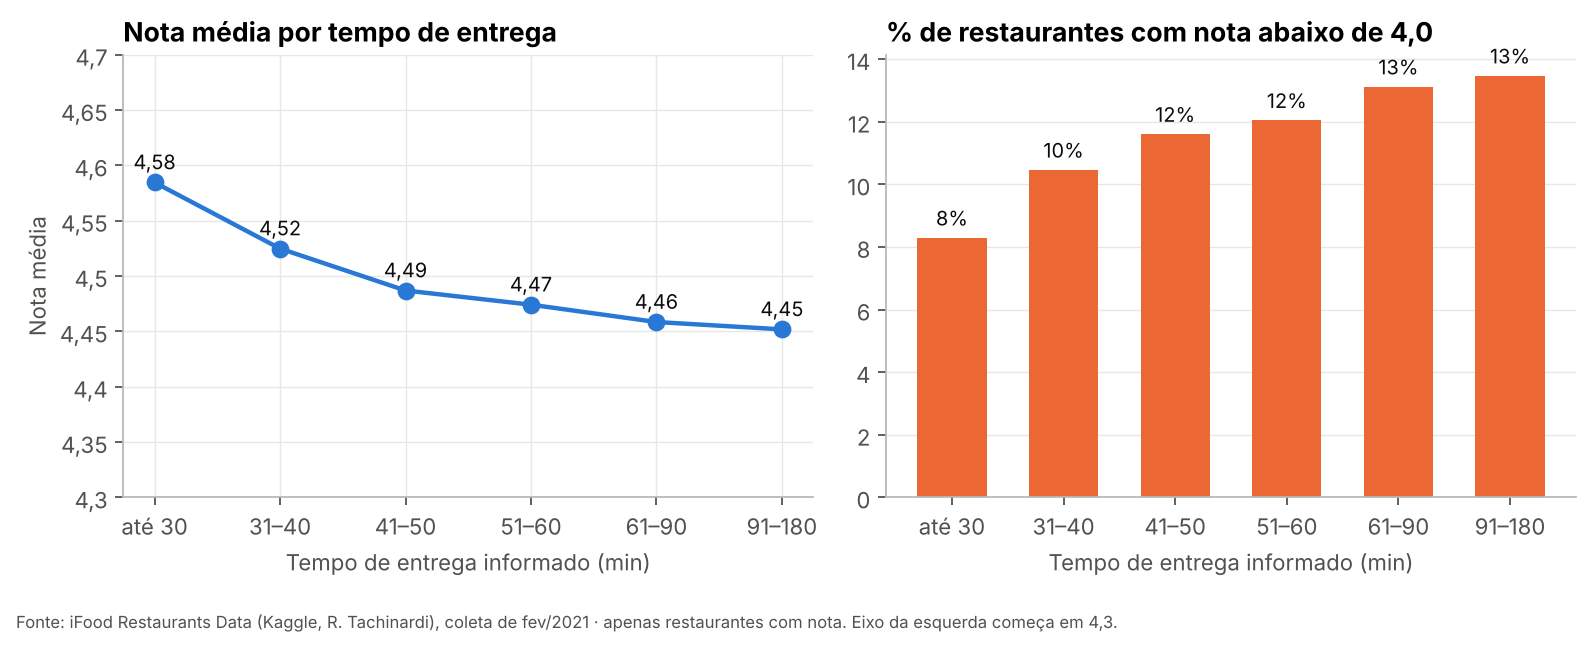

,nota_media,pct_abaixo_4,n
faixa,,,
até 30,4.585,8.290,47756
31–40,4.525,10.458,56887
41–50,4.487,11.600,50493
51–60,4.474,12.041,42993
61–90,4.459,13.115,26557
91–180,4.452,13.465,2436


In [8]:
tempo = analise.fig_tempo_vs_nota(fev)
display(Image("../figures/02_tempo_entrega_vs_nota.png"))
tempo.round(3)

In [9]:
com_nota[["nota", "tempo_entrega", "taxa_entrega", "distancia_km", "pedido_minimo"]] \
    .corr(method="spearman")["nota"].drop("nota").round(3)

tempo_entrega   -0.100
taxa_entrega     0.075
distancia_km     0.021
pedido_minimo   -0.068
Name: nota, dtype: float64

Restaurantes com entrega mais lenta têm nota um pouco menor: **4,58 até 30 min contra 4,45 acima de 90 min**, e a fatia com
nota abaixo de 4,0 passa de **8% para 13%**. A tendência é consistente, mas **o efeito é pequeno** (correlação de Spearman de -0,10).

Taxa de entrega, distância e pedido mínimo praticamente não se relacionam com a nota.

*Cuidado:* o tempo é o informado pelo app **no ponto de busca usado na coleta**, não o tempo real de cada pedido.

In [10]:
frete = com_nota.groupby("frete_gratis")["nota"].agg(["mean", "size"]).round(3)
frete.index = ["Com taxa", "Frete grátis"]
frete

,mean,size
Com taxa,4.528,195318
Frete grátis,4.403,31924


Uma curiosidade: restaurantes com **frete grátis têm nota menor** (4,40 contra 4,53). Uma hipótese é que frete grátis seja
usado como incentivo por quem tem menos tração na plataforma, mas a base não permite testar isso.

### 3.3 Categorias

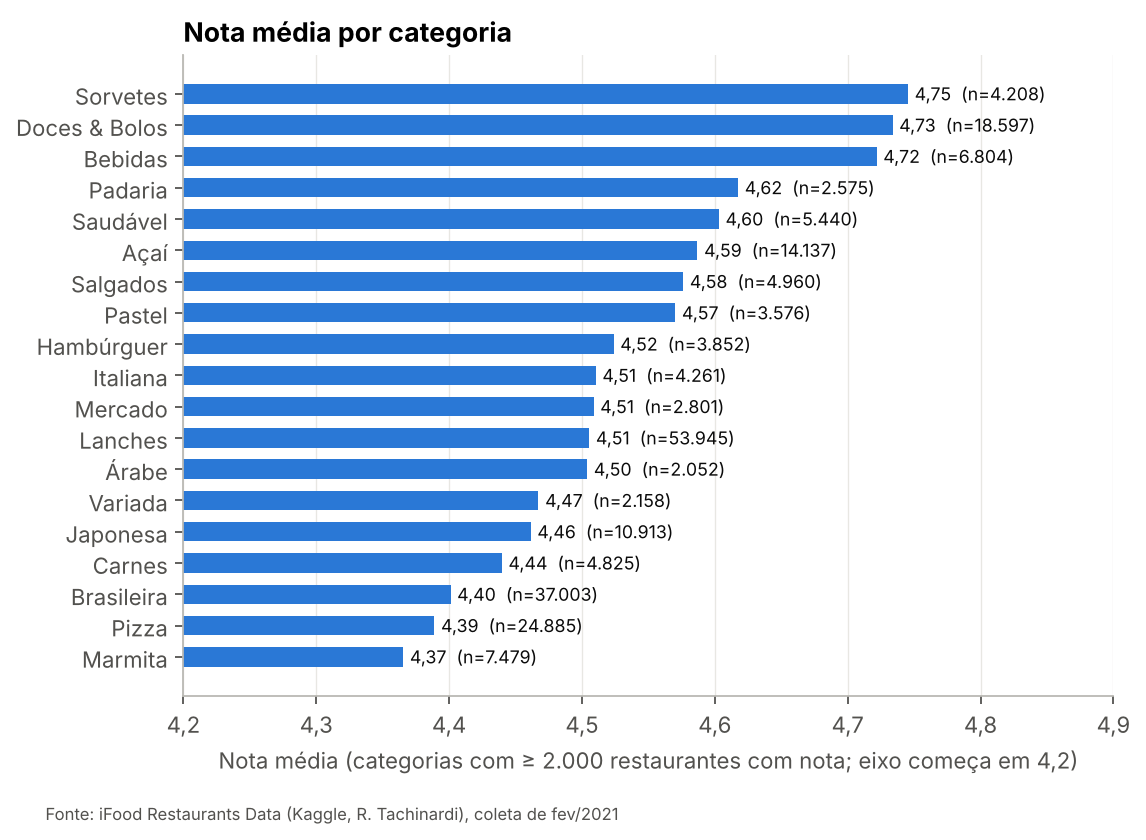

,nota_media,tempo_mediano,n
categoria,,,
Marmita,4.37,41.0,7479
Pizza,4.39,50.0,24885
Brasileira,4.40,41.0,37003
Carnes,4.44,42.0,4825
Japonesa,4.46,50.0,10913
Variada,4.47,45.0,2158
Árabe,4.50,45.0,2052
Lanches,4.51,48.0,53945
Mercado,4.51,53.0,2801


In [11]:
cats = analise.fig_categorias(fev)
display(Image("../figures/03_categorias.png"))
cats.round(2)

A categoria separa mais as notas do que o tempo de entrega: **Sorvetes, Doces & Bolos e Bebidas ficam acima de 4,7**,
enquanto **Marmita, Pizza e Brasileira ficam perto de 4,4**.

Faz sentido: produtos prontos ou industrializados (bebida, sorvete) têm pouca margem para erro. Refeições completas
dependem de temperatura, ponto e montagem, e chegam com mais chance de decepcionar.

### 3.4 Distribuição geográfica

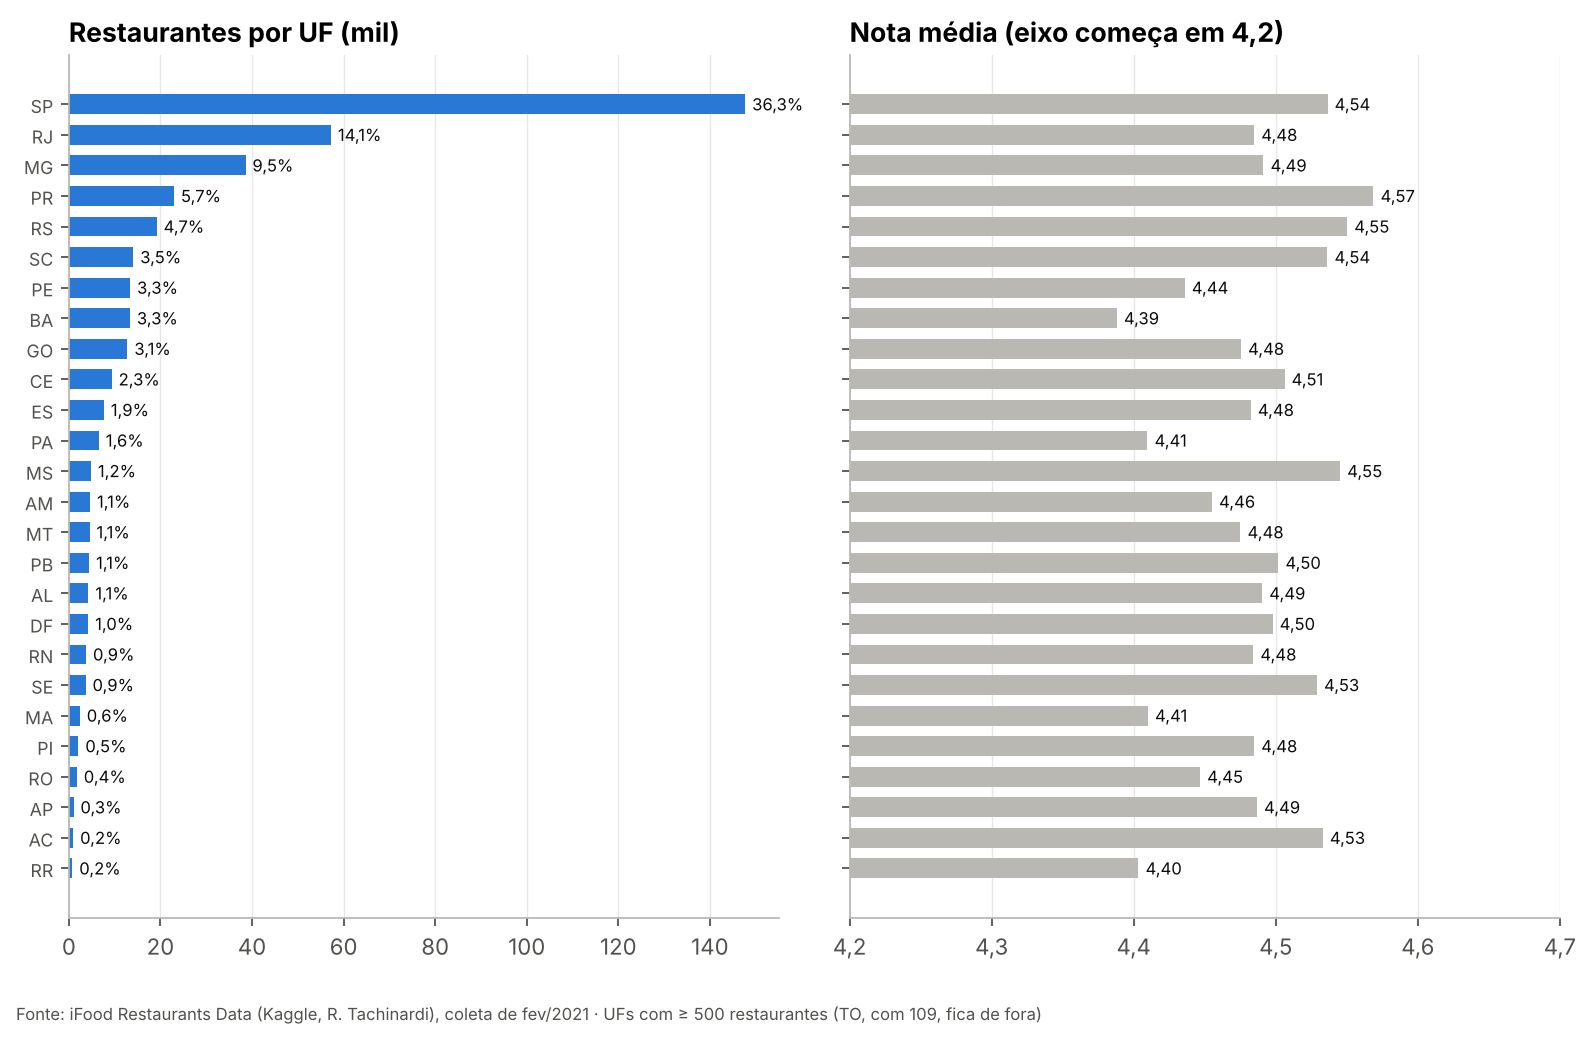

,restaurantes,pct_com_nota,nota_media,tempo_mediano,taxa_mediana,regiao,pct_da_base
uf,,,,,,,
SP,147721,58.48,4.54,46.0,6.00,Sudeste,36.35
RJ,57253,52.25,4.48,47.0,5.00,Sudeste,14.09
MG,38578,54.94,4.49,49.0,5.99,Sudeste,9.49
PR,22972,61.60,4.57,45.0,6.00,Sul,5.65
RS,19200,59.45,4.55,45.0,6.99,Sul,4.72
SC,14080,61.06,4.54,45.0,5.99,Sul,3.46
PE,13390,51.41,4.44,47.0,6.99,Nordeste,3.29
BA,13358,48.82,4.39,44.0,6.99,Nordeste,3.29
GO,12801,52.88,4.48,45.0,6.90,Centro-Oeste,3.15


In [12]:
analise.fig_uf(fev)
display(Image("../figures/04_estados.png"))
analise.tabela_uf(fev).head(10).round(2)

A oferta é muito concentrada: **São Paulo tem 36% dos restaurantes** e o Sudeste, 62%. As notas médias por estado variam
pouco (cerca de 4,4 a 4,6), com o Sul um pouco acima e alguns estados do Nordeste e do Norte um pouco abaixo.

*Limitação:* a cobertura depende dos pontos usados na coleta. Tocantins, por exemplo, aparece com só 109 restaurantes,
o que indica falha de cobertura, e não ausência real de restaurantes.

### 3.5 O que mudou entre nov/2020 e fev/2021

In [13]:
nov2, fev2, entrada, saida, pares = analise.comparar_coletas(fev, nov)
print(f"nov/2020: {len(nov):,}  ->  fev/2021: {len(fev):,}  ({len(fev)/len(nov)-1:+.1%})")
print(f"Entraram: {fev2['entrou'].sum():,} ({fev2['entrou'].mean():.1%} da base de fev)")
print(f"Saíram:   {nov2['saiu'].sum():,} ({nov2['saiu'].mean():.1%} da base de nov)")

nov/2020: 361,447  ->  fev/2021: 406,399  (+12.4%)
Entraram: 60,790 (15.0% da base de fev)
Saíram:   15,838 (4.4% da base de nov)


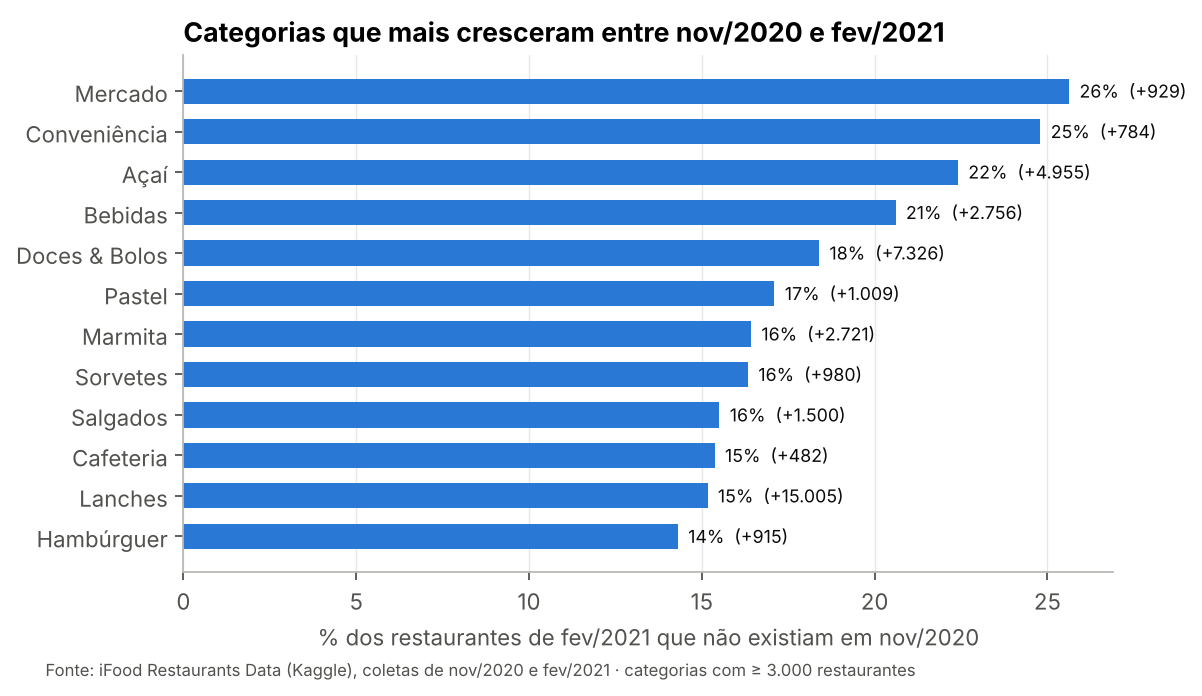

In [14]:
analise.fig_entrada(entrada)
display(Image("../figures/05_crescimento_categorias.png"))

Em três meses, a base cresceu **12%**: entraram cerca de 61 mil restaurantes e saíram 16 mil. O crescimento foi puxado por
**Mercado e Conveniência** (um quarto da base dessas categorias era novo) e por produtos de verão, como **Açaí e Bebidas**.
Isso combina com a época (dezembro a fevereiro) e com a expansão do iFood para além de refeições.

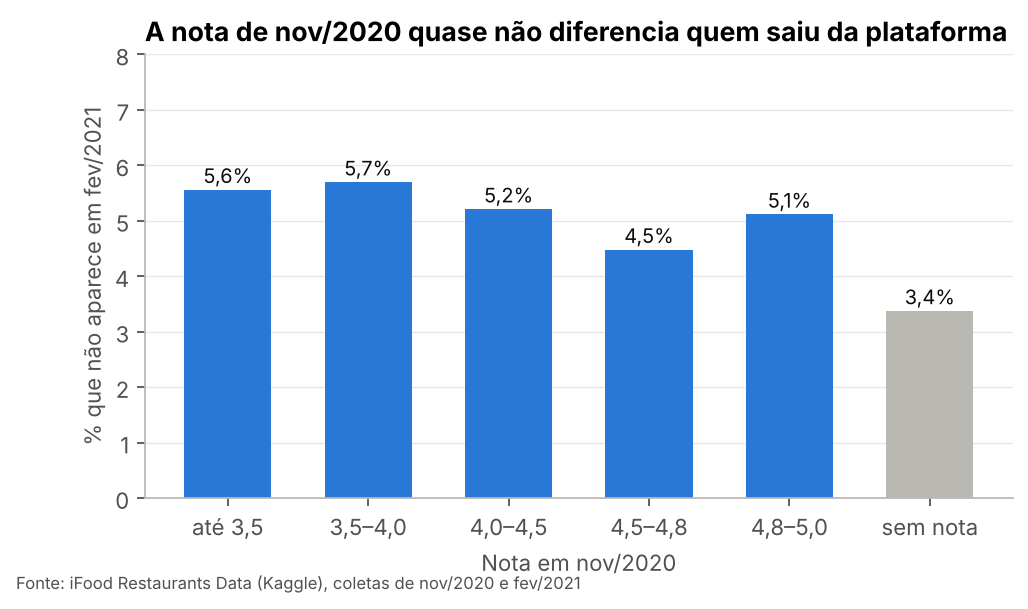

,pct,n
faixa_nota,,
"até 3,5",5.6,11651
"3,5–4,0",5.7,16795
"4,0–4,5",5.2,47341
"4,5–4,8",4.5,63761
"4,8–5,0",5.1,81452


In [15]:
taxa_sem_nota = nov2.loc[~nov2["tem_nota"], "saiu"].mean() * 100
analise.fig_saida(saida, taxa_sem_nota)
display(Image("../figures/06_saida_por_nota.png"))
saida.round(1)

**Resultado contraintuitivo:** a nota de nov/2020 quase não diferencia quem saiu da plataforma. A taxa de saída fica entre
4,5% e 5,7% em todas as faixas de nota. Restaurantes mal avaliados não "somem" muito mais do que os bem avaliados,
pelo menos num intervalo de três meses.

In [16]:
perdeu = (pares["tem_nota_nov"] & ~pares["tem_nota_fev"]).sum()
ganhou = (~pares["tem_nota_nov"] & pares["tem_nota_fev"]).sum()
print(f"Tinham nota em nov e ficaram sem em fev: {perdeu:,}")
print(f"Não tinham nota em nov e passaram a ter: {ganhou:,}")

Tinham nota em nov e ficaram sem em fev: 34,424
Não tinham nota em nov e passaram a ter: 12,475


Outro sinal de que "sem nota" não é sinônimo de "restaurante novo": **34 mil restaurantes tinham nota em nov/2020 e ficaram
sem nota em fev/2021**. A explicação mais provável é que o app só mostra a nota quando há avaliações recentes suficientes.
Isso reforça a decisão de tratar o zero como ausência de nota.

## 4. Conclusões

| # | Insight | Implicação |
|---|---|---|
| 1 | **44% dos restaurantes não exibem nota.** Tratar o zero como nota derruba a média de 4,51 para 2,52 | Qualquer análise de nota precisa separar "sem nota" de "nota baixa" antes de tudo |
| 2 | As notas são **concentradas no topo**: mediana 4,67 e 22% com 5,0 | A nota média diferencia pouco; vale combinar com outros sinais (volume de avaliações, recompra, reclamações) |
| 3 | Entrega mais lenta se associa a nota menor (4,58 → 4,45), mas o **efeito é pequeno** | Tempo importa, mas não explica sozinho a avaliação |
| 4 | **A categoria pesa mais que o tempo:** doces, sorvetes e bebidas ~4,7; marmita e pizza ~4,4 | Comparar restaurantes dentro da mesma categoria, não contra a média geral |
| 5 | A base cresceu **12% em 3 meses**, puxada por **Mercado, Conveniência, Açaí e Bebidas** | Expansão para além de refeições e efeito do verão |
| 6 | **A nota não diferenciou quem saiu** (taxa de saída ~5% em todas as faixas) | A saída de parceiros parece ser movida por outros fatores, como volume de pedidos e custo |

## 5. Limitações e próximos passos

- **Nível restaurante, não pedido:** sem comentários, sem número de avaliações, sem nota por pedido.
- **Tempo e taxa são do ponto de busca** da coleta, não da entrega real.
- **Cobertura geográfica desigual** (ex.: Tocantins), definida pelos pontos usados na coleta.
- **Dados de 2020–2021**, durante a pandemia: os padrões atuais podem ser diferentes.
- **Correlação ≠ causalidade** em todos os cruzamentos.
- **Próximos passos:** cruzar com população por cidade (IBGE) para medir a densidade de restaurantes; e, com dados de
  comentários, classificar os temas das reclamações com um LLM, como no projeto
  [analise-comentarios-restaurantes](https://github.com/Luizamiller/analise-comentarios-restaurantes).